# Jamboree Education – Graduate Admission Prediction

## 1. Problem Statement

### Business Understanding

Jamboree Education helps students prepare for competitive exams such as GRE, GMAT, and SAT to pursue higher education abroad.

They have introduced a feature on their website that allows students to estimate their chances of getting admitted to graduate universities based on their academic performance and application profile.

As part of this analysis, we want to understand which factors influence admission chances and build a model that can predict the probability of admission for prospective students.

### Objective

- Understand which factors have the strongest relationship with admission chances.
- Explore how academic performance and application credentials influence admission probability.
- Identify relationships and correlations among the different variables.
- Build a Linear Regression model to estimate admission chances.
- Provide insights that could help students identify areas where they can improve their applications.

### Target Variable

**Chance of Admit:** The probability of admission, ranging from 0 to 1.

This is the variable we want to predict.

### Independent Variables

| Variable | Description |
|---|---|
| GRE Score | GRE score out of 340 |
| TOEFL Score | TOEFL score out of 120 |
| University Rating | Rating of the undergraduate university (1–5) |
| SOP | Strength of Statement of Purpose (1–5) |
| LOR | Strength of Letters of Recommendation (1–5) |
| CGPA | Undergraduate GPA (out of 10) |
| Research | Research experience (0 = No, 1 = Yes) |

**Note:** `Serial No.` is a unique identifier and will be dropped since it has no meaningful contribution to predicting admission chances.

### Questions We Want to Answer

1. Which factors appear to influence admission chances the most?
2. Do higher GRE scores, TOEFL scores, and CGPA translate into better admission prospects?
3. Does having research experience make a noticeable difference?
4. How important are SOP, LOR, and university ratings?
5. Are any of the independent variables strongly correlated with each other?
6. Can we build a reasonably accurate model to estimate admission chances?

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
df = pd.read_csv('Jamboree_Admission.csv')

In [54]:
df.shape

(500, 9)

In [55]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [57]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


### Initial Dataset Inspection – Observations

1. The dataset contains **500 observations and 9 columns**.
2. All columns have 500 non-null entries, indicating that there are no missing values.
3. The dataset consists of 5 integer columns and 4 floating-point columns.
4. `Serial No.` is a unique identifier and will not be useful for our analysis.
5. `GRE Score` and `TOEFL Score` have relatively high average values, suggesting that the dataset primarily contains academically competitive applicants.
6. Applicants have university ratings ranging from 1 to 5, indicating variation in their undergraduate university backgrounds.
7. The average SOP and LOR ratings are approximately 3.37 and 3.48, respectively, suggesting moderately strong application credentials.
8. The average CGPA is approximately 8.58, indicating generally strong academic performance.
9. The average `Chance of Admit` is approximately 0.72, suggesting that applicants in this dataset generally have relatively high admission chances.

### Variable Classification

For our analysis, the following variables have categorical or ordinal characteristics:

- `Research`: Binary variable (0 = No, 1 = Yes).
- `University Rating`: Ordinal variable ranging from 1 to 5.
- `SOP`: Ordinal rating ranging from 1 to 5.
- `LOR`: Ordinal rating ranging from 1 to 5.

Although these variables are stored as integers or floating-point numbers, their values represent categories or ordered ratings.

We can retain their numerical representations for our initial Linear Regression analysis.

## 2. Univariate Analysis

### 2.1 Distribution of numerical variables
Let's start with histograms and KDE plots.

Variables to analyse:
- GRE Score
- TOEFL Score
- SOP
- LOR
- CGPA
- Chance of Admit

In [58]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [59]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


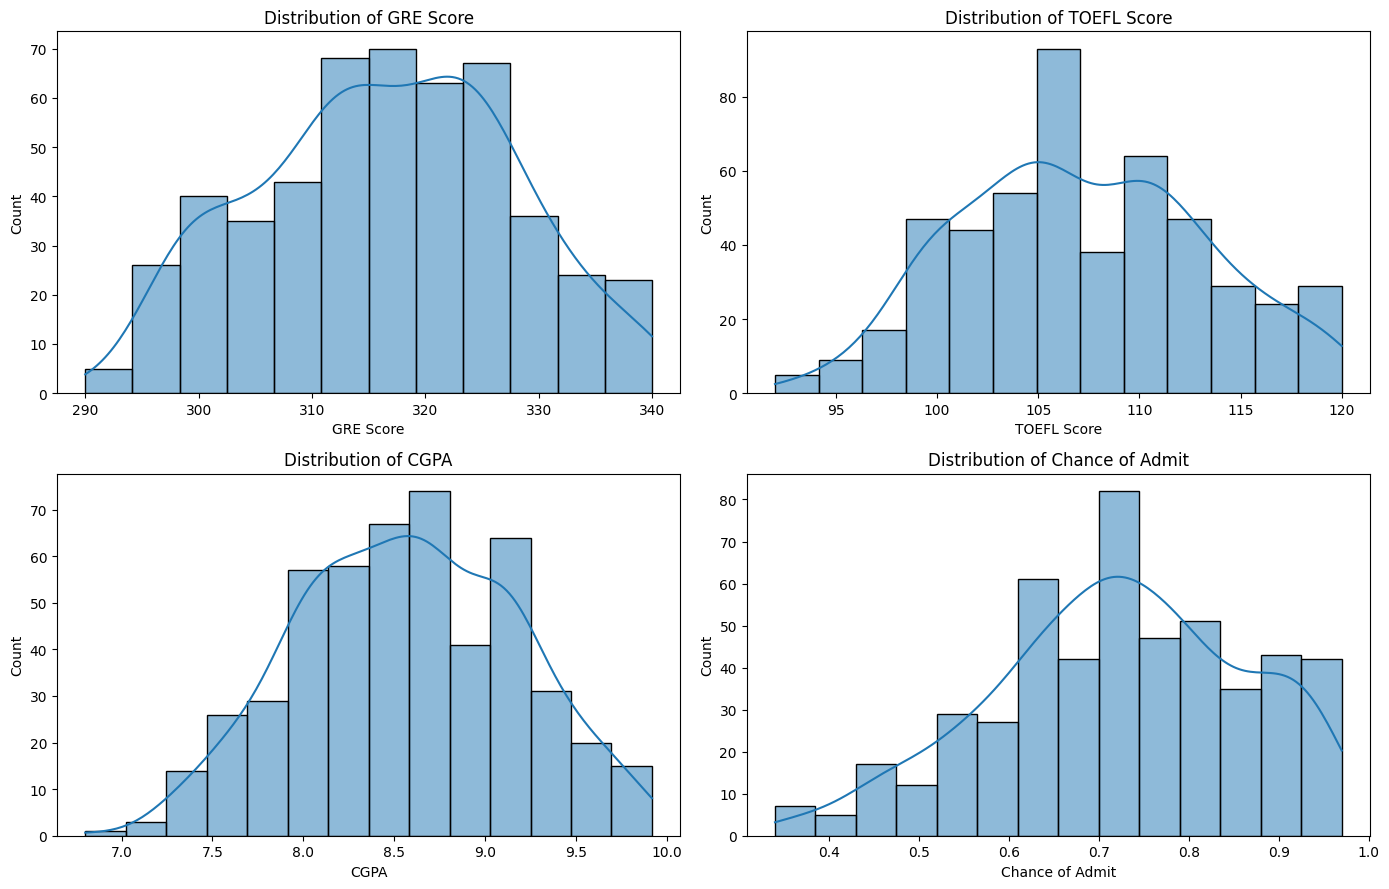

In [60]:
# Numerical variables for distribution analysis
numerical_cols = ['GRE Score', 'TOEFL Score', 'CGPA', 'Chance of Admit']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

### Observations - Distribution of Numerical Variables

1. **GRE Score:** Most applicants have GRE scores between 310 and 330, with the distribution approximately bell-shaped and centered around 315–325.

2. **TOEFL Score:** Scores are concentrated between 100 and 115, with most applicants scoring around 105–110.

3. **CGPA:** Most applicants have a CGPA between 8.0 and 9.2, indicating relatively strong academic performance across the dataset.

4. **Chance of Admit:** Most admission probabilities lie between 0.60 and 0.90, with the highest concentration around 0.70–0.75.

5. Overall, the numerical variables show reasonable variation across applicants. No obvious extreme outliers can be established from these histograms alone; we will examine that further using boxplots.

### 2.2 Distribution of ordinal and categorical variables

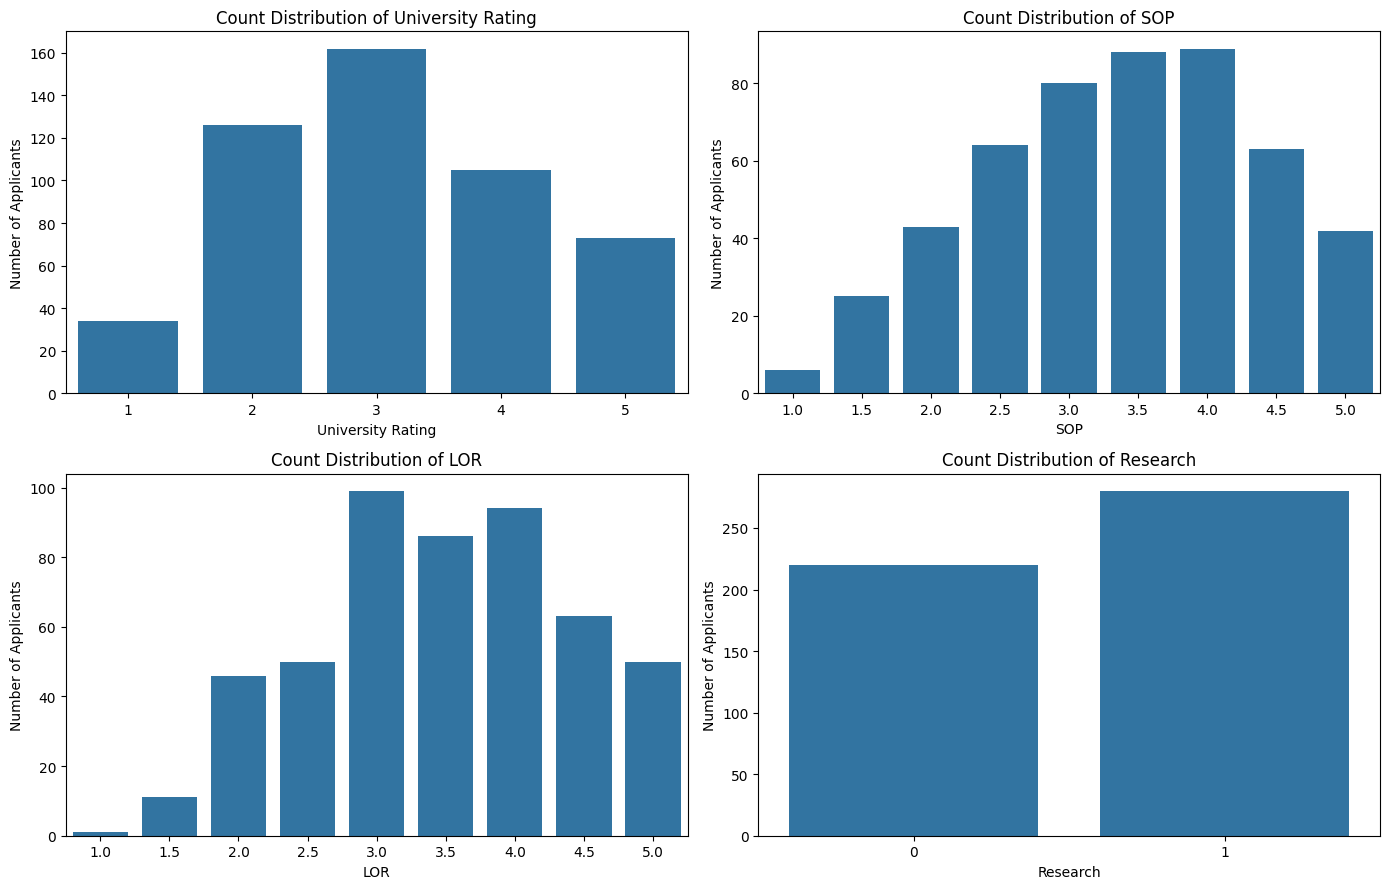

In [61]:
categorical_cols = ['University Rating', 'SOP', 'LOR', 'Research']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Count Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Number of Applicants')

plt.tight_layout()
plt.show()

### Observations - Distribution of Ordinal and Categorical Variables
1. University Rating: Rating 3 is the most common, followed by ratings 2 and 4. Ratings 1 and 5 have comparatively fewer applicants.
2. SOP: Most applicants have SOP ratings between 3 and 4, indicating generally moderate-to-strong SOP evaluations.
3. LOR: Most applicants have LOR ratings of 3 or 4. Very few applicants have a rating of 1.
4. Research: 56% of applicants have research experience, while 44% do not. Both categories are reasonably represented.

### 2.3 Boxplots - Identifying potential outliers

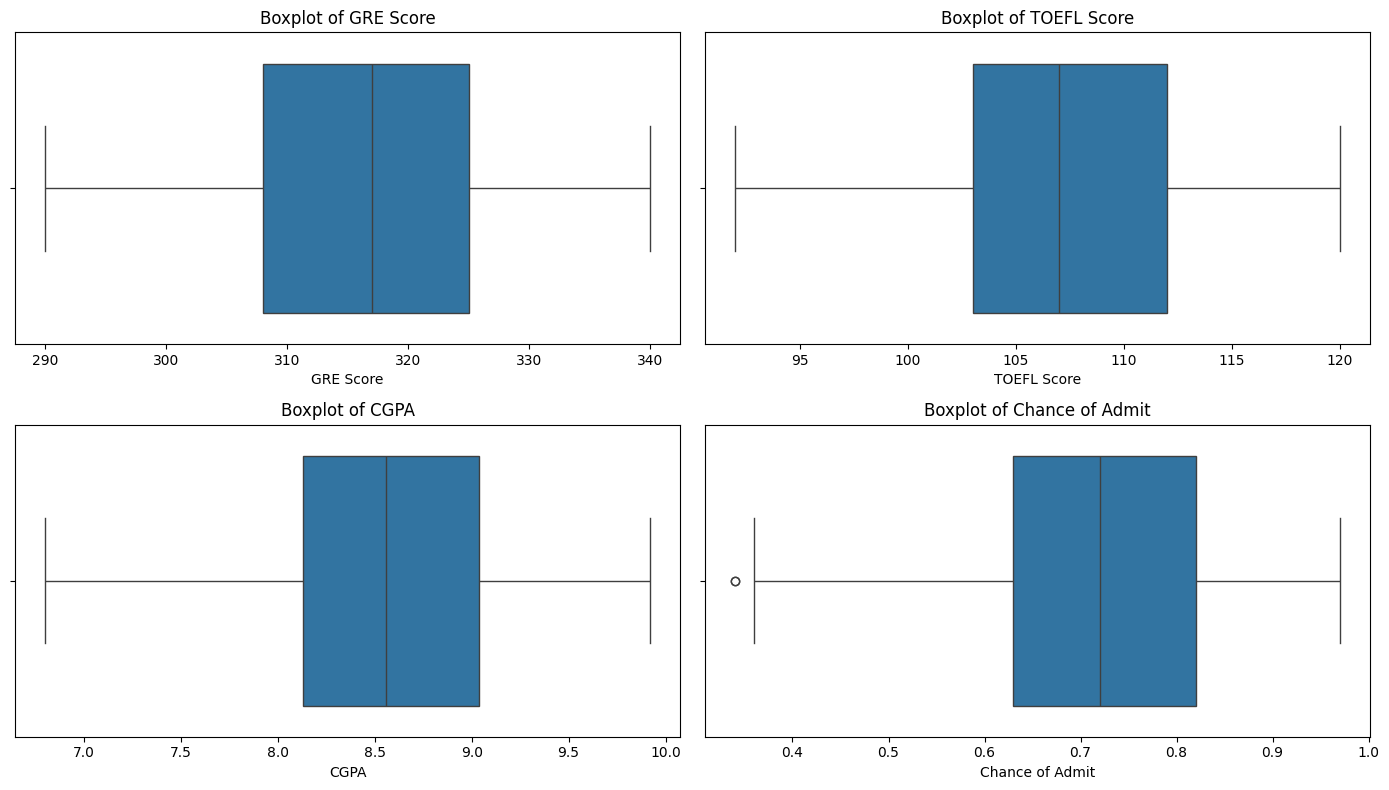

In [62]:
boxplot_cols = ['GRE Score', 'TOEFL Score', 'CGPA', 'Chance of Admit']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(boxplot_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

### Observations - Identifying Potential Outliers
1. GRE Score: No apparent outliers. Scores are distributed across the observed range.
2. TOEFL Score: No apparent outliers.
3. CGPA: No apparent outliers, with most values concentrated between approximately 8.1 and 9.0.
4. Chance of Admit: One potential lower-end outlier is visible around 0.34. The remaining observations fall within the whiskers.

## 3. Bivariate Analysis
Our primary interest is understanding how academic and application-related factors relate to Chance of Admit.

### 3.1 Numerical variables vs Chance of Admit

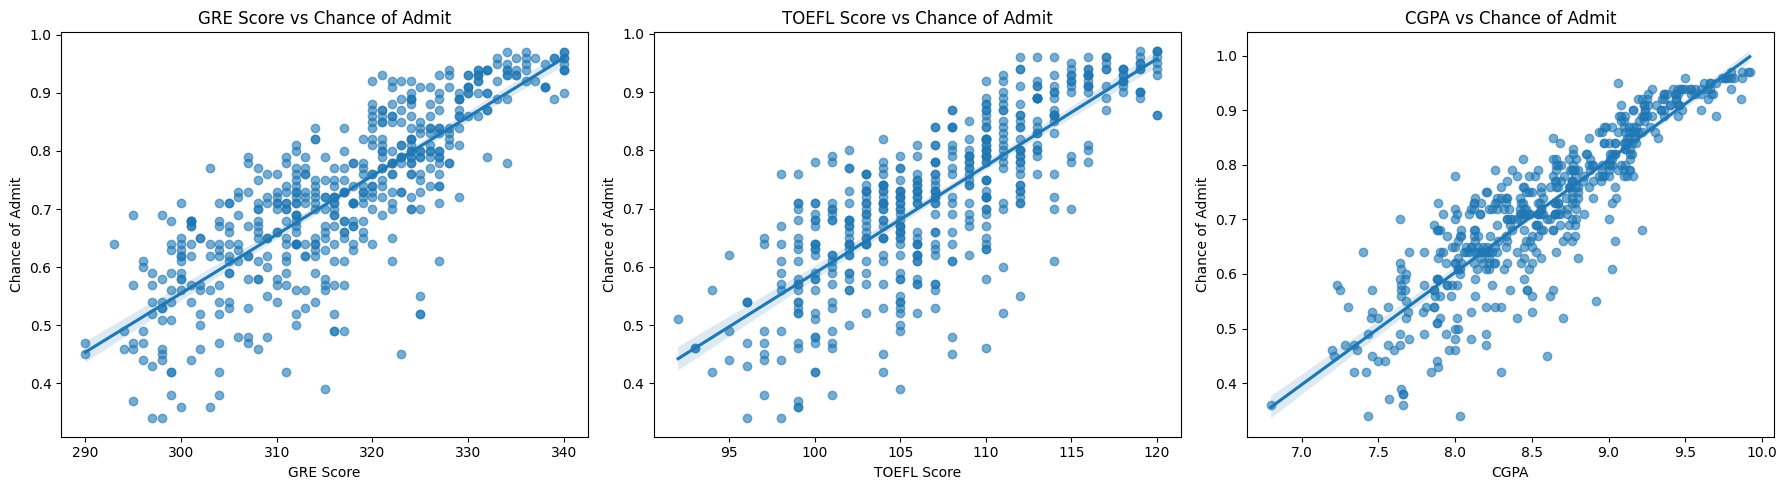

In [63]:
predictors = ['GRE Score', 'TOEFL Score', 'CGPA']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(predictors):
    sns.regplot(
        data=df,
        x=col,
        y='Chance of Admit',
        ax=axes[i],
        scatter_kws={'alpha': 0.6}
    )
    axes[i].set_title(f'{col} vs Chance of Admit')

plt.tight_layout()
plt.show()

### Observations
1. GRE Score: Shows a positive relationship with admission probability. Applicants with higher GRE scores generally tend to have higher chances of admission, although there is some spread in the observations.
2. TOEFL Score: Also shows a positive relationship. Admission probability generally increases with TOEFL scores, though the points are somewhat scattered.
3. CGPA: Shows a strong positive and approximately linear relationship with admission probability. The points are relatively closely clustered around the regression line.

Key takeaway: CGPA appears to have the strongest visual relationship with admission probability among these three variables.

### 3.2 Ordinal variables vs Chance of Admit

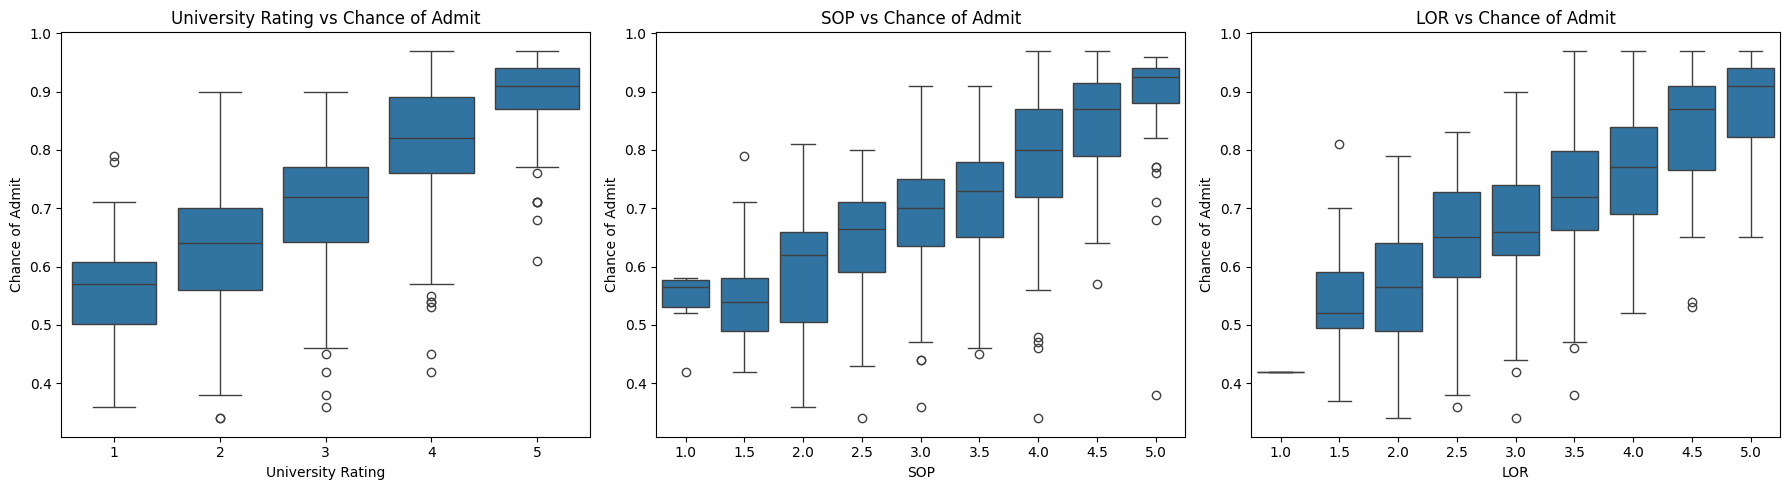

In [64]:
ordinal_cols = ['University Rating', 'SOP', 'LOR']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(ordinal_cols):
    sns.boxplot(
        data=df,
        x=col,
        y='Chance of Admit',
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs Chance of Admit')

plt.tight_layout()
plt.show()

### Observations
1. University Rating: The median admission probability generally increases with university rating. Applicants from higher-rated universities tend to have better admission prospects.
2. SOP: Higher SOP ratings generally correspond to higher median admission probabilities. The trend is particularly noticeable from ratings 2 to 5.
3. LOR: A similar increasing trend is visible. Applicants with stronger recommendation ratings generally have higher median admission probabilities.

### 3.3 Research experience vs Chance of Admit

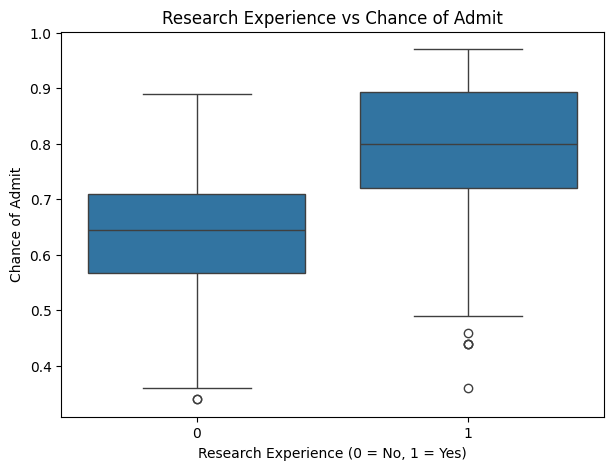

In [65]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Research',
    y='Chance of Admit'
)

plt.title('Research Experience vs Chance of Admit')
plt.xlabel('Research Experience (0 = No, 1 = Yes)')
plt.ylabel('Chance of Admit')

plt.show()

### Observations
1. Applicants with research experience have a higher median admission probability (approximately 0.80) compared to those without research experience (approximately 0.65).
2. The distribution for applicants with research experience is generally shifted towards higher admission probabilities.
3. However, there is some overlap between the two groups, indicating that research experience alone does not determine admission chances.

### 3.4 Correlation analysis
Finally, let's examine the correlations between all numerical variables.

In [66]:
df.drop(columns=['Serial No.'], inplace=True, errors='ignore')

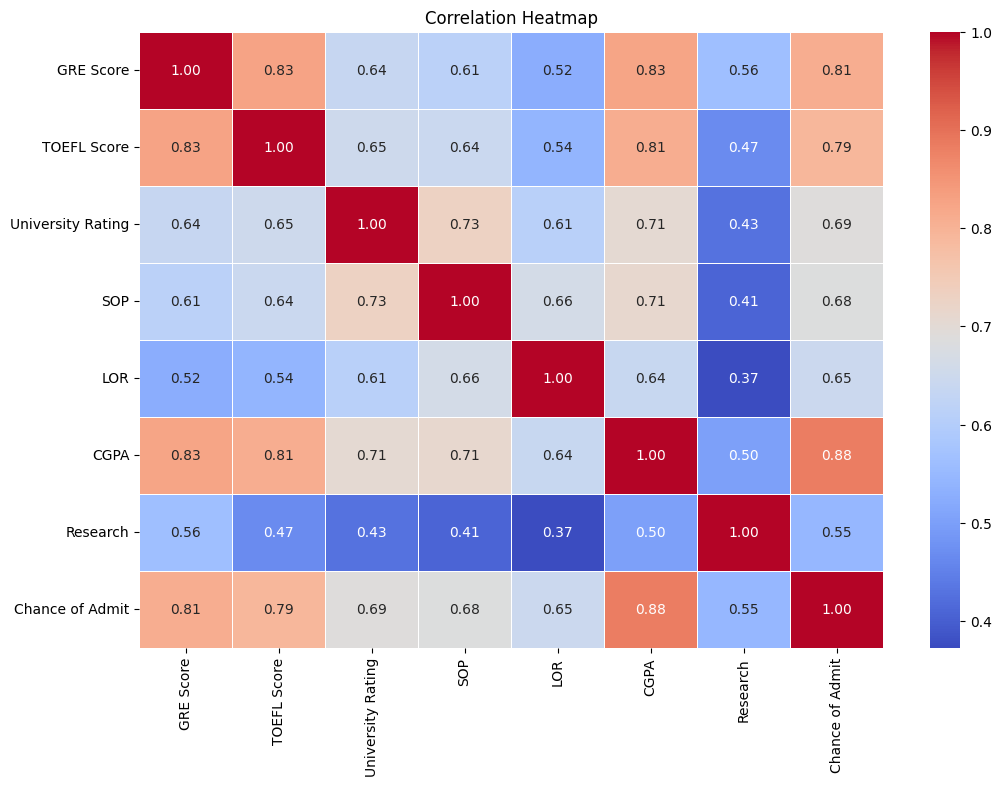

In [67]:
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

### Observations - Correlation Analysis

1. CGPA has the strongest positive correlation with Chance of Admit (0.88), followed by GRE Score (0.81) and TOEFL Score (0.79).
2. University Rating (0.69), SOP (0.68), and LOR (0.65) also show positive correlations with admission probability.
3. Research has a moderate positive correlation with Chance of Admit (0.55).
4. GRE Score and TOEFL Score (0.83), GRE Score and CGPA (0.83), and TOEFL Score and CGPA (0.81) show strong correlations with each other.

These relationships suggest potential multicollinearity among some independent variables, which will be investigated using VIF during regression diagnostics.

## 4. EDA Summary

After exploring the dataset through univariate, bivariate, and correlation analysis, we can draw the following observations:

1. **Dataset Quality:** The dataset contains 500 applicants and 9 columns, with no missing values. Inconsistent whitespace in column names was standardized. `Serial No.` is an identifier and is not useful for prediction.

2. **Applicant Profile:** Most applicants have relatively strong academic profiles, with GRE scores concentrated around 310–330, TOEFL scores around 100–115, and CGPAs primarily between 8.0 and 9.2.

3. **Application Credentials:** University Rating 3 is the most common. SOP and LOR ratings are largely concentrated around 3 and 4. Additionally, 56% of applicants have research experience.

4. **Admission Probability:** Most applicants have admission probabilities between 0.60 and 0.90, with a median around 0.72. The distribution indicates that most applicants in this dataset have moderately high admission prospects.

5. **Relationship with Academic Performance:** GRE Score, TOEFL Score, and CGPA all show positive relationships with admission probability. CGPA has the strongest correlation with the target variable (0.88), followed by GRE Score (0.81) and TOEFL Score (0.79).

6. **Relationship with Application Credentials:** Higher University Ratings, SOP ratings, and LOR ratings are generally associated with higher admission probabilities. Applicants with research experience also tend to have higher admission probabilities than those without it.

7. **Correlation and Multicollinearity:** Several independent variables are strongly correlated with each other. For example, GRE Score and TOEFL Score have a correlation of 0.83, while GRE Score and CGPA also have a correlation of 0.83. These relationships indicate potential multicollinearity, which needs further investigation.

8. **Potential Outliers:** The boxplots show no apparent outliers in GRE Score, TOEFL Score, or CGPA. However, a potential lower-end outlier is visible in Chance of Admit. This will be investigated during preprocessing.

### Conclusion

The EDA suggests that academic performance, particularly CGPA, GRE Score, and TOEFL Score, has a strong positive association with admission probability. Application credentials and research experience also show positive relationships with the target variable.

These findings provide a foundation for building a Linear Regression model. In the next stage, we will prepare the data for modelling, investigate potential outliers, and address any preprocessing requirements before training the model.

## 5. Data Preprocessing

In [68]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

Missing values:
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

Duplicate rows: 0

Data types:
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object

Columns:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


### Observations – Data Quality Checks

- No missing values were found in the dataset.
- No duplicate records were identified.
- All columns have appropriate numerical data types.
- Column names are standardized and consistent.
- The `Serial No.` identifier has already been removed since it has no predictive value.

**Conclusion:** The dataset is clean in terms of missing values, duplicate records, data types, and column naming. No additional cleaning is required at this stage.

### 5.2 Outlier Investigation

During EDA, we noticed one potential lower-end outlier in Chance of Admit.

Now let's investigate outliers systematically using the Interquartile Range (IQR) method.


In [69]:
numerical_cols = [
    'GRE Score', 'TOEFL Score', 'CGPA',
    'Chance of Admit'
]

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower Bound:", round(lower_bound, 3))
    print("Upper Bound:", round(upper_bound, 3))
    print("Number of Outliers:", len(outliers))


GRE Score
Lower Bound: 282.5
Upper Bound: 350.5
Number of Outliers: 0

TOEFL Score
Lower Bound: 89.5
Upper Bound: 125.5
Number of Outliers: 0

CGPA
Lower Bound: 6.759
Upper Bound: 10.409
Number of Outliers: 0

Chance of Admit
Lower Bound: 0.345
Upper Bound: 1.105
Number of Outliers: 2


For Chance of Admit:
- Lower bound: 0.345
- Upper bound: 1.105
- Two observations fall outside these bounds.
- Since the upper bound exceeds 1.0, only values below 0.345 can be outliers.
- The two observations are likely very close to the minimum value of 0.34.
Let's inspect those two observations

Before deciding whether to remove or retain them, let's identify the records and examine their other features.

In [70]:
Q1 = df['Chance of Admit'].quantile(0.25)
Q3 = df['Chance of Admit'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Chance of Admit'] < lower_bound) |
    (df['Chance of Admit'] > upper_bound)
]

outliers

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
92,298,98,2,4.0,3.0,8.03,0,0.34
376,297,96,2,2.5,2.0,7.43,0,0.34


### Observations – Outlier Investigation

1. No outliers were detected in GRE Score, TOEFL Score, or CGPA using the IQR method.
2. Two potential lower-end outliers were identified in Chance of Admit, both having an admission probability of 0.34.
3. On inspecting these records, both applicants were found to have comparatively lower academic scores and no research experience.
4. The observations appear to be valid records rather than data-entry errors.

**Decision:** Both observations will be retained, as they represent legitimate applicants with lower admission probabilities. Removing them could result in the loss of useful information.

## 5.3 Feature and Target Separation

In [71]:
# Separate independent variables and target variable

X = df.drop(columns=['Chance of Admit'])
y = df['Chance of Admit']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 7)
Target shape: (500,)


### Observations – Feature and Target Separation

1. The independent variable dataset (`X`) contains 500 observations and 7 predictor variables.
2. The target variable (`y`) contains 500 observations of `Chance of Admit`.
3. `Serial No.` and `Chance of Admit` are excluded from the independent variables to avoid using an identifier or target as a predictor.

The dataset is now ready for train-test splitting.

## 5.4 Train-Test Split

We'll split the dataset into:
- 80% training data: 400 observations.
- 20% testing data: 100 observations.

The model will learn from the training data, while the test data will be used to evaluate how well it performs on unseen applicants.

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (400, 7)
X_test: (100, 7)
y_train: (400,)
y_test: (100,)


### Observations – Train-Test Split

1. The dataset was split into 80% training data and 20% testing data.
2. The training set contains 400 observations, while the testing set contains 100 observations.
3. All seven independent variables and the target variable are correctly separated.
4. `random_state=42` was used to ensure reproducibility of the split.

The training data will be used to build the model, while the testing data will be reserved for evaluating its performance on unseen observations.

## 5.5 Feature Scaling

In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (400, 7)
Scaled testing shape: (100, 7)


### Observations - Feature Scaling

1. StandardScaler was used to standardize the seven independent variables.
2. The scaler was fitted on the training data and then applied to both training and testing data to prevent data leakage.
3. The scaled training and testing datasets contain 400 and 100 observations, respectively, with all seven features retained.
4. The original unscaled datasets were preserved for use in OLS regression.

Feature scaling prepares the data for Ridge and Lasso regression, where regularization is sensitive to the scale of the input features.

### 5.6 Feature Engineering

After examining the available variables, no additional features or transformations were considered necessary at this stage.

The following decisions were made:

1. **Ordinal Variables:** University Rating, SOP, and LOR were retained in their existing numerical form (1–5), as their values represent an ordered scale.
2. **Binary Variable:** Research was retained in its existing 0/1 representation. No additional encoding was required.
3. **Continuous Variables:** GRE Score, TOEFL Score, and CGPA were retained without transformation.
4. **Feature Creation:** No new features were created, as the existing variables already capture the relevant academic and application-related information.
5. **Target Variable:** Chance of Admit was retained in its original form.

**Conclusion:** No additional feature engineering was required before the initial Linear Regression model. Further transformations or feature creation can be explored later if model diagnostics indicate a need.

## 5.7 Data Preprocessing - Summary

The dataset was prepared for Linear Regression through the following steps:

1. **Data Quality Checks:** No missing values or duplicate records were found. Column names and data types were verified.

2. **Outlier Investigation:** The IQR method identified two potential lower-end outliers in Chance of Admit. After inspecting their profiles, both observations were retained as they appeared to be valid records.

3. **Feature and Target Separation:** The dataset was divided into seven independent variables (`X`) and one target variable (`y`). The `Serial No.` identifier was excluded.

4. **Train-Test Split:** The data was divided into 80% training data (400 observations) and 20% testing data (100 observations), using `random_state=42`.

5. **Feature Scaling:** StandardScaler was fitted on the training data and applied to both training and testing datasets to prevent data leakage.

The dataset is now prepared for regression modelling.

## 6. Model Building

### 6.1 Baseline Linear Regression
Objective: Build our first Linear Regression model using Scikit-learn.

We'll start with a simple baseline model before exploring statistical significance, multicollinearity, and regularization.

Since we already have:
- X_train and X_test — original, unscaled features.
- y_train and y_test — target values.
- X_train_scaled and X_test_scaled — standardized features.

Let's use the original, unscaled features for our initial Linear Regression model. This will also make the coefficients easier to interpret.

In [74]:
from sklearn.linear_model import LinearRegression

# Initialize the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

print("Model training completed!")

Model training completed!


### 6.2 - Model Evaluation.

In [75]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Training set evaluation
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

# Testing set evaluation
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print("Training Performance")
print(f"MAE:  {train_mae:.4f}")
print(f"MSE:  {train_mse:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R2:   {train_r2:.4f}")

print("\nTesting Performance")
print(f"MAE:  {test_mae:.4f}")
print(f"MSE:  {test_mse:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2:   {test_r2:.4f}")

Training Performance
MAE:  0.0425
MSE:  0.0035
RMSE: 0.0594
R2:   0.8211

Testing Performance
MAE:  0.0427
MSE:  0.0037
RMSE: 0.0609
R2:   0.8188


### Interpretation

The baseline Linear Regression model achieved an R² score of **0.8211 on the training set** and **0.8188 on the testing set**.

The testing MAE of 0.0427 indicates that the model's predictions differ from actual admission chances by approximately 4.27 percentage points on average. The testing RMSE is 0.0609.

The similar performance across training and testing datasets suggests that the model generalizes well and does not show significant signs of overfitting.

**Conclusion:** The baseline model explains approximately 81.88% of the variation in admission chances on unseen data, providing a good starting point for further analysis and improvement.

### 6.3 - Coefficient Interpretation

In [76]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_
})

coefficients.loc[len(coefficients)] = [
    'Intercept', lr_model.intercept_
]

coefficients

,Feature,Coefficient
0,GRE Score,0.002434
1,TOEFL Score,0.002996
2,University Rating,0.002569
3,SOP,0.001814
4,LOR,0.017238
5,CGPA,0.112527
6,Research,0.024027
7,Intercept,-1.421447


### Interpretation

The baseline Linear Regression model produced positive coefficients for all seven independent variables, indicating positive relationships with predicted admission chances when other variables are held constant.

- **CGPA** has the largest coefficient (0.1125), suggesting a strong contribution to predicted admission probability per unit increase.
- **Research** has a positive coefficient (0.0240), indicating higher predicted chances for applicants with research experience.
- **LOR** also shows a positive coefficient (0.0172).
- GRE, TOEFL, and University Rating have relatively smaller positive coefficients.

However, the coefficients cannot be directly compared to determine feature importance because the variables have different measurement scales. Correlations among predictors may also influence their individual coefficients.

**Conclusion:** CGPA, Research, and LOR show notable positive coefficients. Further statistical analysis is required before drawing conclusions about feature significance and importance.

## 6.4 - OLS Regression using Statsmodels
Now we'll use Statsmodels to examine information that Scikit-learn's Linear Regression doesn't directly provide, such as:
- p-values and statistical significance
- confidence intervals
- adjusted R²
- F-statistic
- overall model summary

We'll fit OLS using the original, unscaled training features.

In [77]:
import statsmodels.api as sm

# Add constant for the intercept
X_train_ols = sm.add_constant(X_train)

# Fit OLS model
ols_model = sm.OLS(y_train, X_train_ols).fit()

# Display summary
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          3.41e-142
Time:                        07:10:24   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

### 6.4 OLS Regression Analysis

The OLS model achieved an R-squared of **0.821** and an adjusted R-squared of **0.818**, indicating that approximately 81.8% of the variation in admission chances is explained by the predictors, after accounting for the number of features.

The overall F-test p-value is extremely small (3.41e-142), indicating that the model is statistically significant.

At a 5% significance level:
- GRE Score, TOEFL Score, LOR, CGPA, and Research are statistically significant predictors.
- University Rating and SOP are not statistically significant when the other predictors are considered.

The Durbin-Watson statistic of 2.05 does not indicate obvious first-order autocorrelation. However, the Omnibus and Jarque-Bera tests suggest that the residuals may not be normally distributed.

The high condition number (1.37e+04) also raises a potential concern about multicollinearity or differences in feature scales.

**Conclusion:** The model is statistically significant overall, but some predictors are individually insignificant. Further investigation of multicollinearity and residual assumptions is required before finalizing the model.

### 6.5 Multicollinearity – VIF Analysis

In [78]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = X_train.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif_data = vif_data.sort_values(
    by='VIF', ascending=False
)

vif_data

,Feature,VIF
5,CGPA,4.654540
0,GRE Score,4.489983
1,TOEFL Score,3.664298
3,SOP,2.785764
2,University Rating,2.572110
4,LOR,1.977698
6,Research,1.518065


Despite the high correlations we observed in the heatmap, none of the features has a VIF above 5.

### Observations

VIF was calculated to investigate potential multicollinearity among the independent variables.

- CGPA (4.65) and GRE Score (4.49) have the highest VIF values, indicating moderate overlap with other predictors.
- TOEFL Score has a VIF of 3.66, while the remaining variables have values below 3.
- None of the predictors has a VIF exceeding 5.

**Conclusion:** The analysis does not indicate severe multicollinearity among the predictors. Therefore, all seven features are retained for further modelling and evaluation.

### 6.6 - Residual Analysis

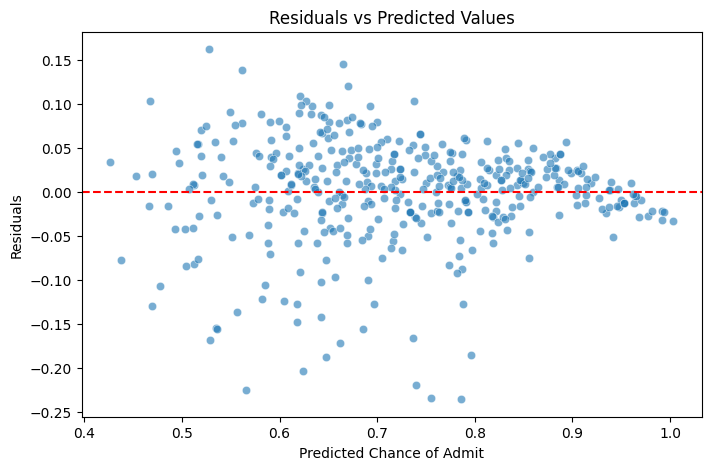

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals on training data
residuals = y_train - y_train_pred

# Residuals vs Predicted Values
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_train_pred,
    y=residuals,
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Chance of Admit')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')

plt.show()

### Residuals vs Predicted Values

The residuals are generally distributed around the zero line, suggesting that the model does not exhibit a strong systematic prediction bias.

However, the spread of residuals appears wider at lower predicted admission probabilities and becomes narrower at higher predicted values. A few observations also show relatively large prediction errors.

This may indicate non-constant residual variance (heteroscedasticity), which requires further investigation.

**Conclusion:** The residual plot shows some encouraging characteristics, but the residual spread is not entirely uniform. Further diagnostic checks are required to assess the Linear Regression assumptions.

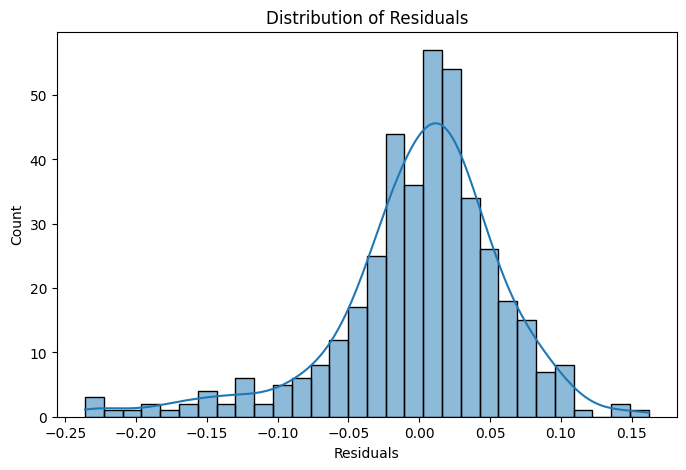

In [80]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True, bins=30)

plt.xlabel('Residuals')
plt.title('Distribution of Residuals')

plt.show()

### Residual Distribution

The residual histogram shows that most errors are concentrated around zero, indicating that the model generally produces relatively small prediction errors.

However, the distribution is not perfectly symmetric and exhibits a longer negative tail, suggesting negative skewness. A few observations also have relatively large negative residuals, indicating instances where the model overestimated admission chances.

This observation is consistent with the Omnibus and Jarque-Bera tests from the OLS summary, which suggest that the residuals deviate from a normal distribution.

**Conclusion:** The residuals are approximately bell-shaped but do not perfectly follow a normal distribution.

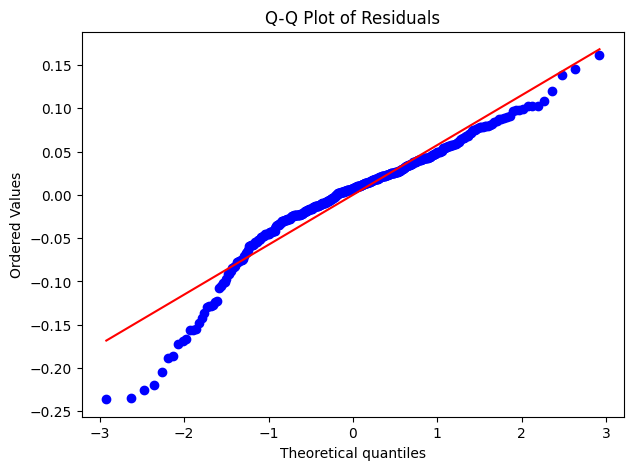

In [81]:
import scipy.stats as stats

plt.figure(figsize=(7, 5))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title('Q-Q Plot of Residuals')
plt.show()

### Q-Q Plot Analysis

The Q-Q plot shows that most residuals follow the reference line reasonably well around the centre of the distribution.

However, noticeable deviations occur at both tails, particularly the lower tail, where the points fall below the reference line. This indicates that the residuals do not perfectly follow a normal distribution and exhibit a heavier negative tail.

**Conclusion:** The Q-Q plot confirms the departure from normality suggested by the residual histogram and OLS normality tests. However, this does not necessarily affect the model's ability to make useful predictions.

## 6.7 - Ridge Regression

In [82]:
from sklearn.linear_model import Ridge

# Initialize Ridge Regression
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_scaled, y_train)

# Generate predictions
ridge_train_pred = ridge_model.predict(X_train_scaled)
ridge_test_pred = ridge_model.predict(X_test_scaled)

print("Ridge model training completed!")

Ridge model training completed!


In [83]:
# Training performance
ridge_train_mae = mean_absolute_error(y_train, ridge_train_pred)
ridge_train_rmse = np.sqrt(mean_squared_error(y_train, ridge_train_pred))
ridge_train_r2 = r2_score(y_train, ridge_train_pred)

# Testing performance
ridge_test_mae = mean_absolute_error(y_test, ridge_test_pred)
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))
ridge_test_r2 = r2_score(y_test, ridge_test_pred)

print("Ridge Training Performance")
print(f"MAE:  {ridge_train_mae:.4f}")
print(f"RMSE: {ridge_train_rmse:.4f}")
print(f"R2:   {ridge_train_r2:.4f}")

print("\nRidge Testing Performance")
print(f"MAE:  {ridge_test_mae:.4f}")
print(f"RMSE: {ridge_test_rmse:.4f}")
print(f"R2:   {ridge_test_r2:.4f}")

Ridge Training Performance
MAE:  0.0425
RMSE: 0.0594
R2:   0.8211

Ridge Testing Performance
MAE:  0.0427
RMSE: 0.0609
R2:   0.8188


### 6.7 Ridge Regression – Baseline Model

A Ridge Regression model was trained using standardized features with an initial alpha value of 1.0.

The model achieved a testing MAE of 0.0427, RMSE of 0.0609, and R² of 0.8188. These results are identical to the baseline Linear Regression model up to the reported precision.

This suggests that the initial regularization strength did not produce a meaningful change in predictive performance.

**Conclusion:** Further tuning of the alpha parameter is required to determine whether Ridge Regression can improve model performance.

### 6.7.1 Ridge Hyperparameter Tuning

Tune the alpha parameter
Let's experiment with different regularization strengths.

We'll use GridSearchCV with 5-fold cross-validation to find a suitable alpha value.

Important: We'll use only the training data for tuning. Our test data will remain untouched until final evaluation.

In [84]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
import numpy as np

# Define alpha values to experiment with
alpha_values = {
    'alpha': np.logspace(-3, 3, 50)
}

# Initialize Ridge model
ridge = Ridge()

# Perform 5-fold cross-validation
ridge_grid = GridSearchCV(
    estimator=ridge,
    param_grid=alpha_values,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

# Fit using training data only
ridge_grid.fit(X_train_scaled, y_train)

print("Best Alpha:", ridge_grid.best_params_['alpha'])
print("Best CV RMSE:", -ridge_grid.best_score_)

Best Alpha: 6.25055192527397
Best CV RMSE: 0.06039659891430403


### Ridge Regression – Hyperparameter Tuning

GridSearchCV with 5-fold cross-validation was used to identify the optimal regularization strength.

A total of 50 alpha values, ranging from 0.001 to 1000, were evaluated.

The best alpha value was **6.2506**, with a cross-validation RMSE of **0.0604**.

This indicates that a stronger regularization penalty than the initial alpha of 1.0 may provide better generalization.

**Conclusion:** The optimal alpha was selected using cross-validation on the training data. Its performance will now be evaluated on the unseen test dataset.

### 6.7.2 Evaluate the tuned Ridge model

In [85]:
# Retrieve the best Ridge model
best_ridge_model = ridge_grid.best_estimator_

# Generate predictions
best_ridge_train_pred = best_ridge_model.predict(X_train_scaled)
best_ridge_test_pred = best_ridge_model.predict(X_test_scaled)

# Evaluate test performance
print("Tuned Ridge Testing Performance")
print(f"MAE:  {mean_absolute_error(y_test, best_ridge_test_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_ridge_test_pred)):.4f}")
print(f"R2:   {r2_score(y_test, best_ridge_test_pred):.4f}")

Tuned Ridge Testing Performance
MAE:  0.0429
RMSE: 0.0609
R2:   0.8185


### Tuned Ridge Regression – Evaluation

The Ridge model was evaluated using the optimal alpha value of 6.2506 obtained through 5-fold cross-validation.

The tuned model achieved a testing MAE of 0.0429, RMSE of 0.0609, and R² of 0.8185.

Compared with baseline Linear Regression, Ridge Regression showed a marginally higher MAE and a slightly lower R², while RMSE remained unchanged at the reported precision.

**Conclusion:** Hyperparameter tuning did not result in an improvement in test performance. The baseline Linear Regression model currently performs marginally better.

## 6.8 Lasso Regression

We'll begin with alpha=0.001 rather than 1.0. Lasso's penalty behaves differently from Ridge's, and a smaller starting value is useful for this dataset.

In [86]:
from sklearn.linear_model import Lasso

# Initialize Lasso Regression
lasso_model = Lasso(alpha=0.001, max_iter=10000)

# Train the model
lasso_model.fit(X_train_scaled, y_train)

# Generate predictions
lasso_train_pred = lasso_model.predict(X_train_scaled)
lasso_test_pred = lasso_model.predict(X_test_scaled)

print("Lasso model training completed!")

Lasso model training completed!


In [87]:
print("Lasso Training Performance")
print(f"MAE:  {mean_absolute_error(y_train, lasso_train_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, lasso_train_pred)):.4f}")
print(f"R2:   {r2_score(y_train, lasso_train_pred):.4f}")

print("\nLasso Testing Performance")
print(f"MAE:  {mean_absolute_error(y_test, lasso_test_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, lasso_test_pred)):.4f}")
print(f"R2:   {r2_score(y_test, lasso_test_pred):.4f}")

Lasso Training Performance
MAE:  0.0425
RMSE: 0.0594
R2:   0.8210

Lasso Testing Performance
MAE:  0.0425
RMSE: 0.0608
R2:   0.8192


### 6.8 Lasso Regression – Baseline Model

A Lasso Regression model was trained using standardized features with an initial alpha value of 0.001.

The model achieved a testing MAE of 0.0425, RMSE of 0.0608, and R² of 0.8192.

Compared with baseline Linear Regression and tuned Ridge Regression, Lasso showed marginally better performance across all three evaluation metrics.

**Conclusion:** Lasso Regression currently provides the best test performance among the three models. However, further hyperparameter tuning is required before making a final comparison.

### 6.8.1 Tune Lasso's alpha parameter

In [88]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
import numpy as np

# Define alpha values
alpha_values = {
    'alpha': np.logspace(-4, 1, 50)
}

# Initialize Lasso
lasso = Lasso(max_iter=10000)

# Perform 5-fold cross-validation
lasso_grid = GridSearchCV(
    estimator=lasso,
    param_grid=alpha_values,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

# Fit using training data only
lasso_grid.fit(X_train_scaled, y_train)

print("Best Alpha:", lasso_grid.best_params_['alpha'])
print("Best CV RMSE:", -lasso_grid.best_score_)

Best Alpha: 0.0006551285568595509
Best CV RMSE: 0.06032528107440862


In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(y_actual, y_pred, model_name):
    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_pred)

    print(f"{model_name} Performance")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2:   {r2:.4f}")
    print("-" * 35)

In [90]:
best_lasso_model = lasso_grid.best_estimator_

best_lasso_train_pred = best_lasso_model.predict(X_train_scaled)
best_lasso_test_pred = best_lasso_model.predict(X_test_scaled)

evaluate_model(
    y_train,
    best_lasso_train_pred,
    "Tuned Lasso - Training"
)

evaluate_model(
    y_test,
    best_lasso_test_pred,
    "Tuned Lasso - Testing"
)

Tuned Lasso - Training Performance
MAE:  0.0425
RMSE: 0.0594
R2:   0.8210
-----------------------------------
Tuned Lasso - Testing Performance
MAE:  0.0426
RMSE: 0.0608
R2:   0.8191
-----------------------------------


The Lasso Regression model was optimized using 5-fold cross-validation, resulting in a best alpha value of approximately 0.000655 and a cross-validation RMSE of 0.0603.

The tuned model achieved a testing MAE of 0.0426, RMSE of 0.0608, and R² of 0.8191. Its training and testing performance are very similar, indicating good generalization with no obvious signs of overfitting.

Hyperparameter tuning resulted in only a marginal change in performance compared with the baseline Lasso model. This suggests that the initial alpha value was already close to a suitable regularization strength.

## 6.9 Model Comparison

In [91]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Tuned Ridge',
        'Tuned Lasso'
    ],
    'MAE': [
        0.0427,
        0.0429,
        0.0426
    ],
    'RMSE': [
        0.0609,
        0.0609,
        0.0608
    ],
    'R2': [
        0.8188,
        0.8185,
        0.8191
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,0.0427,0.0609,0.8188
1,Tuned Ridge,0.0429,0.0609,0.8185
2,Tuned Lasso,0.0426,0.0608,0.8191


### Observations
1. The performance of Linear Regression, Ridge Regression, and Lasso Regression was compared using testing MAE, RMSE, and R².

2. Among the three models, Tuned Lasso achieved the best results, with an MAE of 0.0426, RMSE of 0.0608, and R² of 0.8191.

3. However, the performance differences across all three models are marginal. This suggests that regularization through Ridge and Lasso did not provide a substantial improvement over baseline Linear Regression.

4. The baseline Linear Regression model already demonstrates good predictive performance, explaining approximately 81.88% of the variation in admission chances. Tuned Lasso is selected as the best-performing model based on the evaluation metrics, while recognizing that its advantage is very small.

## 7. Testing Linear Regression Assumptions

### 7.1 Check for Linearity

In [92]:
# Step 1: Calculate fitted values and residuals
# Since we've already fitted the OLS model in Section 6.4, let's reuse it.

# Obtain fitted values and residuals from the OLS model
fitted_values = ols_model.fittedvalues
residuals = ols_model.resid

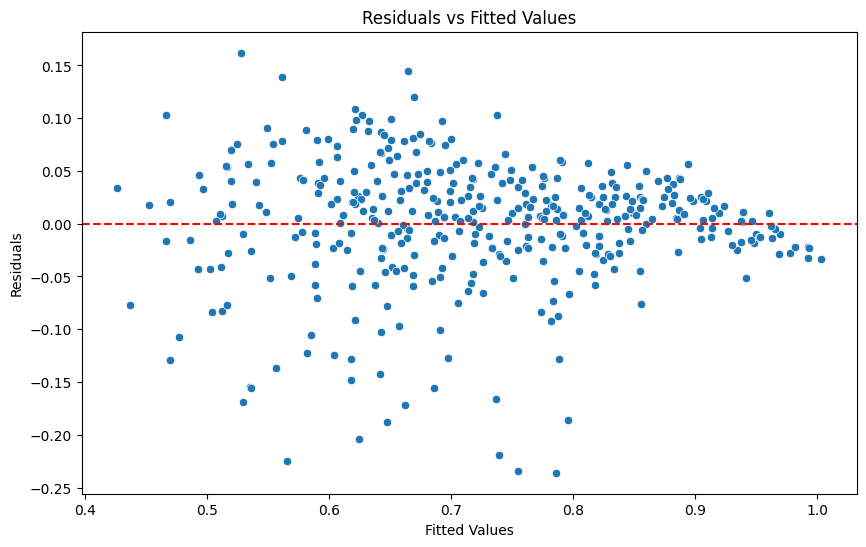

In [93]:
# Step 2: Plot residuals against fitted values

plt.figure(figsize=(10, 6))

sns.scatterplot(x=fitted_values, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')

plt.show()

The residuals-versus-fitted plot was examined to assess the linearity assumption. The residuals are scattered around the zero line without an obvious systematic curved pattern. This suggests that the linearity assumption is reasonably satisfied. The Ramsey RESET test also returned a p-value of 0.3101, greater than 0.05, providing no statistically significant evidence of functional-form misspecification.

In [94]:
from statsmodels.stats.diagnostic import linear_reset

reset_result = linear_reset(ols_model, power=2, use_f=True)

print("RESET Test F-statistic:", reset_result.fvalue)
print("RESET Test p-value:", reset_result.pvalue)

RESET Test F-statistic: 1.0328002297709333
RESET Test p-value: 0.3101303086582425


In [95]:
print(
    "Correlation between fitted values and residuals:",
    ols_model.resid.corr(ols_model.fittedvalues)
)

Correlation between fitted values and residuals: 4.822303619413583e-17


In [96]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = pd.DataFrame()

vif_data['Feature'] = X_train.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif_data = vif_data.sort_values(by='VIF', ascending=False)

print(vif_data.to_string(index=False))

          Feature      VIF
             CGPA 4.654540
        GRE Score 4.489983
      TOEFL Score 3.664298
              SOP 2.785764
University Rating 2.572110
              LOR 1.977698
         Research 1.518065


The linearity assumption was evaluated using the Ramsey RESET test. The test produced an F-statistic of 1.0328 and a p-value of 0.3101. Since the p-value is greater than the 0.05 significance level, we fail to reject the null hypothesis. Therefore, there is no statistically significant evidence of functional-form misspecification, and the linearity assumption is considered reasonably satisfied.

### 7.2 Check for Independence of Errors

In [97]:
mean_residual = ols_model.resid.mean()

print("Mean of Residuals:", mean_residual)

Mean of Residuals: 3.920475055707584e-16


The mean of residuals was calculated using the residuals obtained from the OLS regression model. The resulting mean was 3.92 × 10⁻¹⁶, which is approximately zero. This confirms that the residuals are centered around zero, satisfying the zero-mean residual condition of the Ordinary Least Squares model.

In [98]:
from statsmodels.stats.stattools import durbin_watson

dw_stat = durbin_watson(ols_model.resid)

print("Durbin-Watson Statistic:", dw_stat)

Durbin-Watson Statistic: 2.0495529015329965


The independence of errors was assessed using the Durbin-Watson test. The test produced a statistic of 2.050, which is close to 2, indicating no notable first-order autocorrelation among the residuals. Since the dataset contains cross-sectional observations, independence is also supported by the nature of the data and its sampling process.

### 7.3 - Homoscedasticity.

In [99]:
# Step 1: Perform the Breusch-Pagan test

from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    ols_model.resid,
    ols_model.model.exog
)

labels = ['LM Statistic', 'LM p-value', 'F-Statistic', 'F p-value']

for label, value in zip(labels, bp_test):
    print(f"{label}: {value:.4f}")

LM Statistic: 25.1559
LM p-value: 0.0007
F-Statistic: 3.7582
F p-value: 0.0006


Step 2: Understand the hypotheses
- H₀: The residuals have constant variance (homoscedasticity).
- H₁: The residuals have non-constant variance (heteroscedasticity).

The homoscedasticity assumption was evaluated using the Breusch-Pagan test. The test produced an LM statistic of 25.1559 with a p-value of 0.0007 and an F-statistic of 3.7582 with a p-value of 0.0006. Since both p-values are below the 0.05 significance level, we reject the null hypothesis of constant residual variance. This indicates the presence of heteroscedasticity, suggesting that the residual variance is not constant across observations.

### 7.4 Check for Normality of Residuals

In [100]:
from scipy.stats import jarque_bera

jb_stat, jb_pvalue = jarque_bera(ols_model.resid)

print("Jarque-Bera Statistic:", jb_stat)
print("Jarque-Bera p-value:", jb_pvalue)

Jarque-Bera Statistic: 190.09887364276906
Jarque-Bera p-value: 5.254774460431777e-42


The normality of residuals was evaluated using the Jarque-Bera test. The test produced a statistic of 190.0989 and a p-value of 5.25 × 10⁻⁴². Since the p-value is significantly below the 0.05 significance level, we reject the null hypothesis of normality. This indicates that the residuals are not normally distributed. The negative skewness and elevated kurtosis observed in the OLS summary further support this finding.

### 7.5 Check for Multicollinearity

Multicollinearity was assessed using the Variance Inflation Factor (VIF). All predictors have VIF values below 5, with CGPA having the highest value of 4.65, followed by GRE Score at 4.49. This indicates some moderate correlation among academic performance-related predictors, but no severe multicollinearity. Therefore, all predictors are retained in the model.

### Observations

1. The assumptions of Linear Regression were evaluated using appropriate statistical tests and diagnostic plots.

2. The linearity assumption was reasonably satisfied based on the residuals-versus-fitted plot and the Ramsey RESET test (p-value = 0.3101). The Durbin-Watson statistic of 2.050 indicated no notable first-order autocorrelation. The mean of residuals was also approximately zero.

3. The Breusch-Pagan test (p-value = 0.0007) revealed the presence of heteroscedasticity, while the Jarque-Bera test (p-value = 5.25 × 10⁻⁴²) indicated that the residuals are not normally distributed.

4. VIF analysis showed that all predictors have VIF values below 5, indicating no severe multicollinearity.

5. Despite the violations of homoscedasticity and normality assumptions, the Linear Regression model demonstrates good predictive performance, with a testing R² of approximately 0.819. These violations should be considered when interpreting statistical inference and model reliability.

## 8. Model Performance Evaluation

### 8.1 - Calculate Performance Metrics

In [101]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

# Number of observations and features
n_train = X_train.shape[0]
n_test = X_test.shape[0]
p = X_train.shape[1]

# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)
train_adj_r2 = 1 - (1 - train_r2) * (n_train - 1) / (n_train - p - 1)

# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)
test_adj_r2 = 1 - (1 - test_r2) * (n_test - 1) / (n_test - p - 1)

print("Training Performance")
print(f"MAE: {train_mae:.4f}")
print(f"RMSE: {train_rmse:.4f}")
print(f"R2: {train_r2:.4f}")
print(f"Adjusted R2: {train_adj_r2:.4f}")

print("\nTesting Performance")
print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2: {test_r2:.4f}")
print(f"Adjusted R2: {test_adj_r2:.4f}")

Training Performance
MAE: 0.0425
RMSE: 0.0594
R2: 0.8211
Adjusted R2: 0.8179

Testing Performance
MAE: 0.0427
RMSE: 0.0609
R2: 0.8188
Adjusted R2: 0.8051


The Linear Regression model achieved a training MAE of 0.0425 and testing MAE of 0.0427, indicating an average prediction error of approximately 4.3 percentage points. The training and testing RMSE values were 0.0594 and 0.0609, respectively. The model achieved training and testing R² scores of 0.8211 and 0.8188, explaining approximately 82% of the variation in admission chances. The adjusted R² scores were 0.8179 for training and 0.8051 for testing, indicating that the model retains good explanatory power even after accounting for the number of predictors.

### 8.2 - Compare Training and Testing Performance

The training and testing performance metrics are very close across Linear Regression, Ridge Regression, and Lasso Regression. This indicates that all three models generalize well to unseen data, with no significant evidence of overfitting or underfitting. The regularization techniques did not provide a meaningful improvement over the baseline Linear Regression model, as the differences in evaluation metrics are negligible.

### 8.3 – Overall Model Performance

The Linear Regression model demonstrates good predictive performance, achieving a testing R² score of approximately 0.819 and an MAE of 0.0427. Among the three evaluated models, Tuned Lasso performed marginally better, with a testing MAE of 0.0426, RMSE of 0.0608, and R² of 0.8191. However, the improvement over the baseline Linear Regression model is negligible.

The model's average prediction error of approximately 4.3 percentage points indicates that it can provide reasonably accurate estimates of students' admission chances. Therefore, the model is suitable for limited deployment as a decision-support tool to help students assess their admission prospects and make more informed application decisions. However, its predictions should not be treated as guaranteed admission outcomes.

Further improvements could be explored by:
- Collecting more diverse and representative admission data.
- Incorporating additional relevant features, such as undergraduate academic background, university-specific admission requirements, and applicant profiles.
- Exploring non-linear models such as Random Forest and Gradient Boosting to capture complex relationships.
- Validating the model on newer admission datasets and continuously monitoring its predictive performance.

Overall, the model provides a good starting point for Jamboree's student guidance use case, with scope for further improvement through additional data and experimentation.

## 9. Actionable Insights and Recommendations

### 9.1 – Significance and Importance of Predictor Variables

Step 1: Calculate standardized coefficients
Standardized coefficients allow us to compare the relative influence of predictors on a common scale.

In [102]:
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# Standardize the target variable
y_train_scaled = (
    y_train - y_train.mean()
) / y_train.std()

# Use the already standardized training features
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

# Fit OLS using standardized features and target
X_ols_scaled = sm.add_constant(X_train_scaled_df)

standardized_model = sm.OLS(
    y_train_scaled,
    X_ols_scaled
).fit()

# Display standardized coefficients and p-values
standardized_results = pd.DataFrame({
    'Standardized Coefficient': standardized_model.params.drop('const'),
    'P-value': standardized_model.pvalues.drop('const')
})

standardized_results['Absolute Coefficient'] = (
    standardized_results['Standardized Coefficient'].abs()
)

standardized_results = standardized_results.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

standardized_results

,Standardized Coefficient,P-value,Absolute Coefficient
CGPA,0.480785,1.086636e-22,0.480785
GRE Score,0.189739,3.357625e-05,0.189739
TOEFL Score,0.129666,1.619658e-03,0.129666
LOR,0.112870,1.947965e-04,0.112870
Research,0.084947,1.337508e-03,0.084947
University Rating,0.020915,5.414408e-01,0.020915
SOP,0.012720,7.211636e-01,0.012720


### 9.1 – Significance and Importance of Predictor Variables

1. Based on the standardized regression coefficients, CGPA is the most influential predictor of admission chances, with a coefficient of 0.4808. It is followed by GRE Score (0.1897), TOEFL Score (0.1297), LOR (0.1129), and Research (0.0849). All five predictors have statistically significant p-values below 0.05 and show positive associations with admission chances.

2. University Rating (0.0209) and SOP (0.0127) have comparatively smaller coefficients and p-values above 0.05, indicating that they do not have statistically significant independent effects in the fitted model.

3. The VIF analysis shows that all predictors have VIF values below 5, suggesting no severe multicollinearity, although some moderate correlation exists among academic performance variables.

4. From a counselling perspective, Jamboree should prioritize academic performance, standardized test preparation, research exposure, and building strong academic relationships for recommendation letters. Although SOP is not statistically significant in this model, students should still be encouraged to prepare well-structured and personalized statements. University selection should be guided by individual profiles and university requirements.

These findings represent associations identified by the model and should not be interpreted as proof of causation or guarantees of admission.

### 9.2 – Additional Data Sources and Variables

1. The predictive performance of the model could be improved by incorporating additional variables that provide a more comprehensive view of an applicant's profile.

2. Potential variables include undergraduate university, degree specialization, GPA, work experience, internships, research publications, project experience, SOP quality, detailed LOR assessments, extracurricular achievements, and university-specific admission requirements.

3. Jamboree could also enrich its dataset using external sources such as university admission websites, university ranking databases, historical admission records, and public research databases.

4. Additionally, collecting program-specific information, such as acceptance rates, minimum eligibility requirements, and department-level admission criteria, could help the model capture differences across universities and graduate programs.

5. However, Jamboree should ensure that the additional data is reliable, relevant, representative, and collected with appropriate consent. It should also avoid data leakage, address missing values, and evaluate potential biases before incorporating new variables.

6. Overall, a richer dataset containing academic, professional, research, application-related, and university-specific information could help Jamboree develop a more comprehensive and reliable admission prediction model.

### 9.3 - Real-World Implementation and Business Benefits

1. Jamboree can implement the admission prediction model by integrating it into its existing student counselling platform. Students could enter their academic and application-related details to receive estimated admission chances. These predictions could be displayed through a student-facing tool or a counsellor dashboard, helping counsellors understand individual student profiles, identify areas for improvement, and recommend suitable universities.

2. The model could also support personalized counselling strategies, university shortlisting, and targeted marketing campaigns. By providing data-driven recommendations, Jamboree could improve counselling efficiency, student engagement, and the overall application experience.

3. Potential business benefits include higher student conversion rates, improved student satisfaction, better counselling productivity, increased application success rates, and more effective marketing campaigns. These improvements should be measured using business metrics such as lead-to-enrollment conversion rate, counselling turnaround time, student satisfaction, customer acquisition cost, and admission offer rate.

4. For successful deployment, Jamboree should validate the model on recent admission data, integrate it with existing systems through an API, monitor its predictive performance, and periodically retrain it with updated data. The model should initially serve as a decision-support tool, with counsellors retaining responsibility for final recommendations.

5. Overall, deploying an improved admission prediction model could help Jamboree deliver more personalized, efficient, and data-driven counselling services while strengthening its competitive position in the graduate admissions consulting market.